# Phase 1: 資料探索 (EDA) — AI4I 2020 Predictive Maintenance

對應 Issue #2。執行者：AI4I 2020 資料集分析專案

**資料來源**：UCI Machine Learning Repository — "AI4I 2020 Predictive Maintenance Dataset" (Dataset ID 601)
- 下載連結：https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip
- 儲存位置：`data/ai4i2020.csv`

共 10,000 筆、14 個變數。本筆記本完成完整探索性資料分析，並輸出報告 `reports/eda_summary.md`。

In [1]:
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (11, 5)
sns.set_style("whitegrid")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)

print("Libraries loaded.")

Libraries loaded.


In [2]:
DATA_PATH = "/root/data/ai4i2020.csv"
df = pd.read_csv(DATA_PATH)
print(f"Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(5)

Loaded: 10,000 rows x 14 columns


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### 1.1 資料集基本資訊
記錄樣本數、變數名稱、型態、記憶體佔用。

In [3]:
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nDtypes:")
print(df.dtypes)
print("\nMemory usage (KB):", round(df.memory_usage(deep=True).sum() / 1024, 2))

Shape: (10000, 14)

Columns: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dtypes:
UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Memory usage (KB): 1963.02


### 1.2 描述性統計（數值型）

In [4]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


### 1.3 遺失值與重複值檢查

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0]
print("Missing values by column:")
print(missing if len(missing) else "None")
print("Total missing:", int(df.isna().sum().sum()))
print("Duplicated rows:", int(df.duplicated().sum()))

Missing values by column:
None
Total missing: 0
Duplicated rows: 0


## 2. 目標變數：機器故障 (Machine failure)

目標欄位 `Machine failure` 為二元標籤（0=正常，1=故障），另有五個獨立故障模式欄位：TWF, HDF, PWF, OSF, RNF。

In [6]:
print("Machine failure distribution:")
print(df["Machine failure"].value_counts())
print("\nFailure rate:", round(df["Machine failure"].mean(), 4))

failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print("\nFailure mode counts:")
for c in failure_modes:
    print(f"  {c}: {df[c].sum()}")

Machine failure distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure rate: 0.0339

Failure mode counts:
  TWF: 46
  HDF: 115
  PWF: 95
  OSF: 98
  RNF: 19


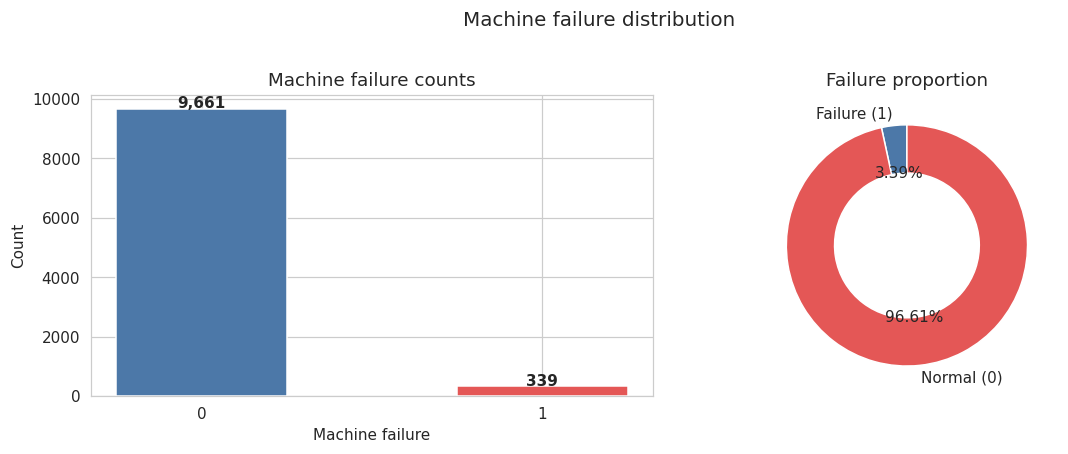

Failure rate: 3.3900% (339 / 10,000)


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

counts = df["Machine failure"].value_counts().sort_index()
colors = ["#4c78a8", "#e45756"]
ax[0].bar(counts.index.astype(str), counts.values, color=colors, width=0.5)
ax[0].set_xlabel("Machine failure")
ax[0].set_ylabel("Count")
ax[0].set_title("Machine failure counts")
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 30, f"{v:,}", ha="center", fontsize=10, fontweight="bold")

rate = df["Machine failure"].mean()
ax[1].pie([rate, 1 - rate], labels=["Failure (1)", "Normal (0)"],
          autopct="%1.2f%%", colors=colors, startangle=90,
          wedgeprops=dict(width=0.4))
ax[1].set_title("Failure proportion")

plt.suptitle("Machine failure distribution", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()
print(f"Failure rate: {rate:.4%} ({int(counts.iloc[1]):,} / {int(counts.sum()):,})")

## 3. 類別型變數：Product ID 與 Type

- Product ID：高基數編碼（L/M/H 開頭 + 序號），共 10,000 筆唯一，主要用途為識別。
- Type：產品品質等級 L（低）、M（中）、H（高），分佈 60% / 30% / 10%。

In [8]:
print("Product ID value counts (top 20):")
print(df["Product ID"].value_counts().head(20))
print("\nType value counts:")
print(df["Type"].value_counts())
print("\nType %:")
print((df["Type"].value_counts(normalize=True) * 100).round(2))
print("\nFailure rate by Type:")
print(df.groupby("Type")["Machine failure"].mean().round(4))

Product ID value counts (top 20):
Product ID
M14860    1
L47181    1
L47182    1
L47183    1
L47184    1
M14865    1
L47186    1
L47187    1
M14868    1
M14869    1
H29424    1
H29425    1
M14872    1
M14873    1
L47194    1
L47195    1
M14876    1
M14877    1
H29432    1
M14879    1
Name: count, dtype: int64

Type value counts:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Type %:
Type
L    60.00
M    29.97
H    10.03
Name: proportion, dtype: float64

Failure rate by Type:
Type
H    0.0209
L    0.0392
M    0.0277
Name: Machine failure, dtype: float64


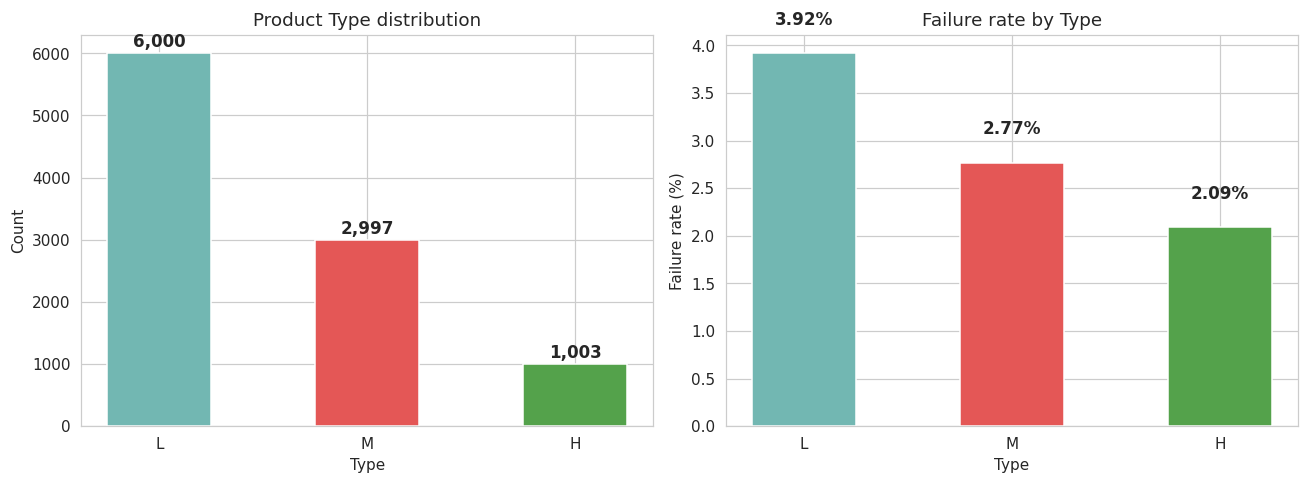

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

type_counts = df["Type"].value_counts().reindex(["L", "M", "H"])
ax[0].bar(type_counts.index, type_counts.values, color=["#72b7b2", "#e45756", "#54a24b"], width=0.5)
ax[0].set_xlabel("Type")
ax[0].set_ylabel("Count")
ax[0].set_title("Product Type distribution")
for i, v in enumerate(type_counts.values):
    ax[0].text(i, v + 100, f"{v:,}", ha="center", fontsize=11, fontweight="bold")

type_fail = df.groupby("Type")["Machine failure"].mean().reindex(["L", "M", "H"])
ax[1].bar(type_fail.index, type_fail.values * 100, color=["#72b7b2", "#e45756", "#54a24b"], width=0.5)
ax[1].set_xlabel("Type")
ax[1].set_ylabel("Failure rate (%)")
ax[1].set_title("Failure rate by Type")
for i, v in enumerate(type_fail.values * 100):
    ax[1].text(i, v + 0.3, f"{v:.2f}%", ha="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

## 4. 數值型變數分佈

氣溫、程序溫度、轉速、扭矩、刀具磨損五個連續/離散數值變數。

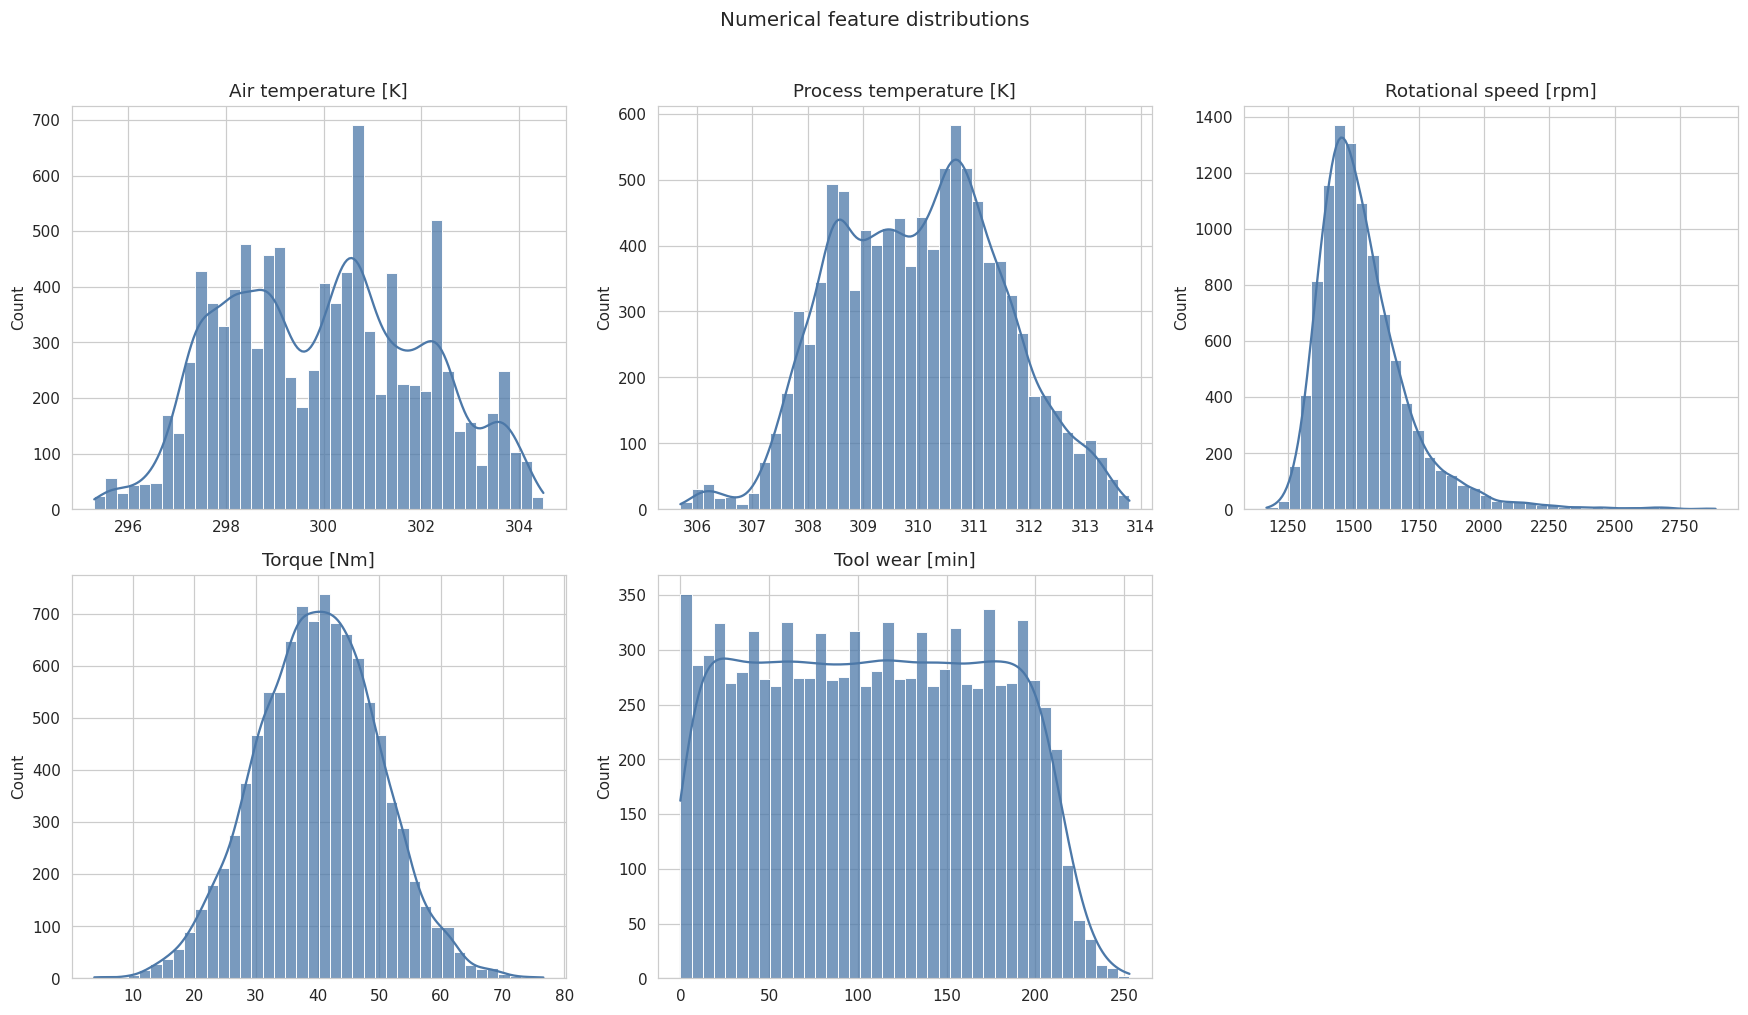

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


In [10]:
num_cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
            "Torque [Nm]", "Tool wear [min]"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, c in enumerate(num_cols):
    sns.histplot(data=df, x=c, bins=40, kde=True, color="#4c78a8", ax=axes[i], alpha=0.75)
    axes[i].set_title(c)
    axes[i].set_xlabel("")
fig.delaxes(axes[-1])
plt.suptitle("Numerical feature distributions", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

df[num_cols].describe()

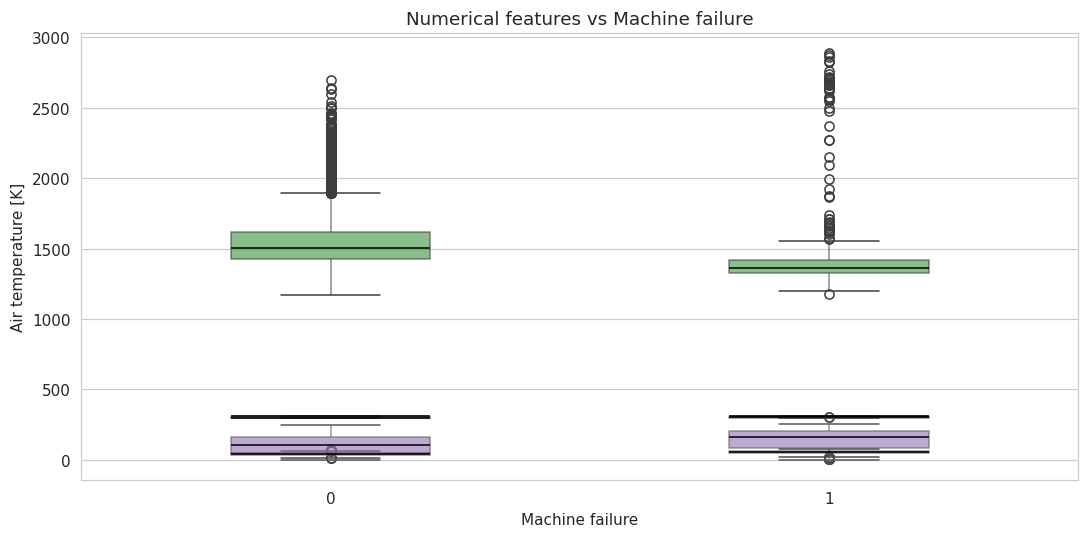

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
# Show boxplots for each feature by failure status
for c in num_cols:
    sns.boxplot(data=df, x="Machine failure", y=c, width=0.4, showcaps=True,
                boxprops=dict(alpha=.6), whiskerprops=dict(alpha=.6),
                medianprops=dict(color="black"), ax=ax)
plt.title("Numerical features vs Machine failure")
plt.tight_layout()
plt.show()

## 5. 相關性分析

計算 Pearson 相關矩陣，並繪製熱力圖。

In [12]:
corr = df.corr(numeric_only=True)
corr.round(3)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
UDI,1.000,0.117,0.324,-0.007,0.003,-0.011,-0.023,0.009,-0.022,-0.024,-0.001,-0.006
Air temperature [K],0.117,1.000,0.876,0.023,-0.014,0.014,0.083,0.010,0.138,0.003,0.002,0.018
Process temperature [K],0.324,0.876,1.000,0.019,-0.014,0.013,0.036,0.007,0.057,-0.003,0.005,0.022
Rotational speed [rpm],-0.007,0.023,0.019,1.000,-0.875,0.000,-0.044,0.010,-0.121,0.123,-0.105,-0.013
Torque [Nm],0.003,-0.014,-0.014,-0.875,1.000,-0.003,0.191,-0.015,0.143,0.084,0.183,0.016
Tool wear [min],-0.011,0.014,0.013,0.000,-0.003,1.000,0.105,0.116,-0.001,-0.009,0.156,0.011
Machine failure,-0.023,0.083,0.036,-0.044,0.191,0.105,1.000,0.363,0.576,0.523,0.531,0.005
TWF,0.009,0.010,0.007,0.010,-0.015,0.116,0.363,1.000,-0.007,0.009,0.038,0.031
HDF,-0.022,0.138,0.057,-0.121,0.143,-0.001,0.576,-0.007,1.000,0.018,0.046,-0.005
PWF,-0.024,0.003,-0.003,0.123,0.084,-0.009,0.523,0.009,0.018,1.000,0.116,-0.004


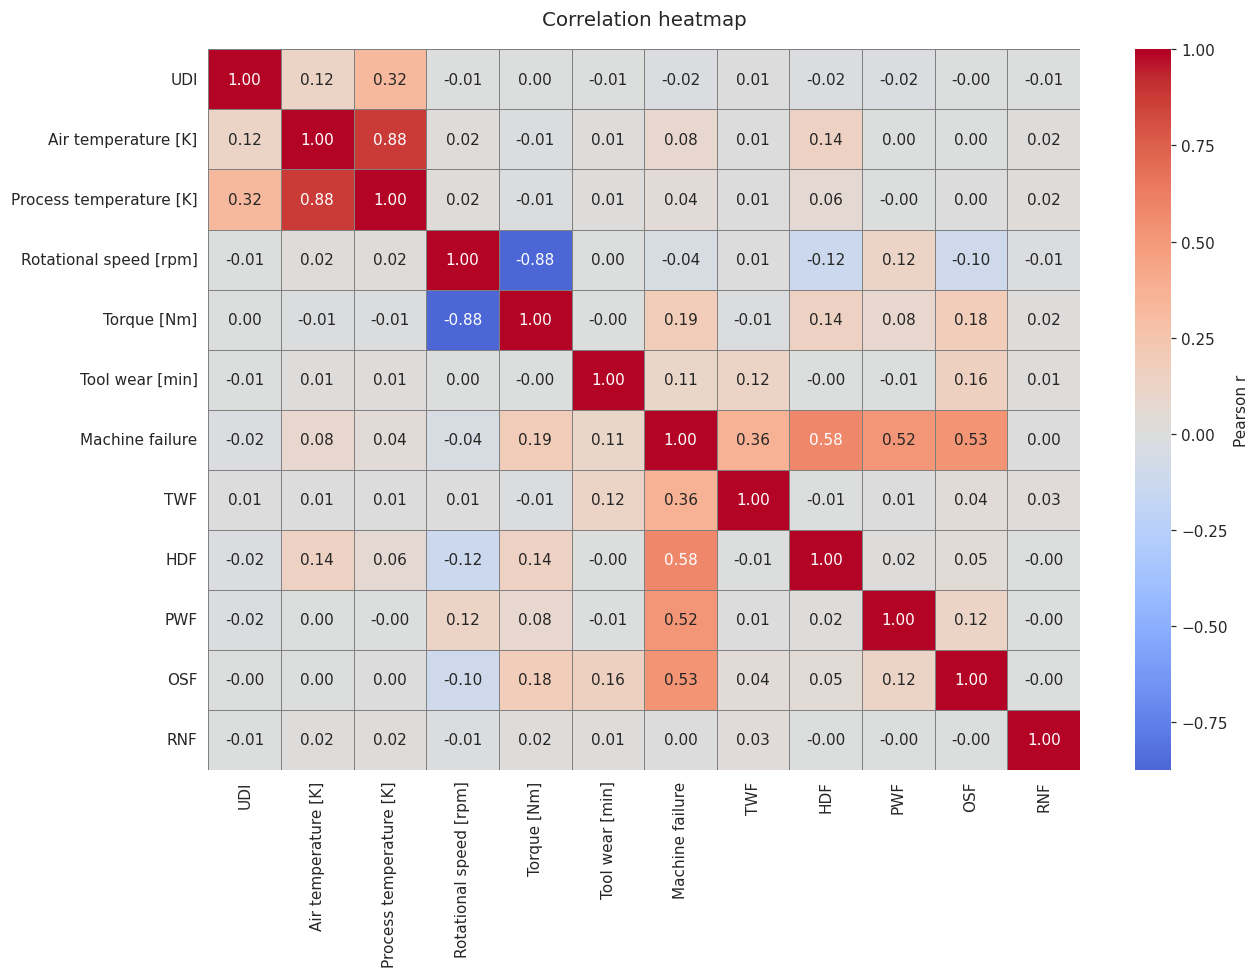

Top correlations with Machine failure (abs):
HDF                        0.5758
OSF                        0.5311
PWF                        0.5228
TWF                        0.3629
Torque [Nm]                0.1913
Tool wear [min]            0.1054
Air temperature [K]        0.0826
Rotational speed [rpm]     0.0442
Process temperature [K]    0.0359
UDI                        0.0229
RNF                        0.0045
Name: Machine failure, dtype: float64


In [13]:
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, linecolor="gray", cbar_kws={"label": "Pearson r"}, ax=ax)
plt.title("Correlation heatmap", fontsize=13, pad=16)
plt.tight_layout()
plt.show()

print("Top correlations with Machine failure (abs):")
target_corr = corr["Machine failure"].abs().sort_values(ascending=False)
print(target_corr[1:].round(4))

## 6. 特徵與目標變數的關係

逐一觀察各數值特徵與故障標籤的關係（小提琴圖）。

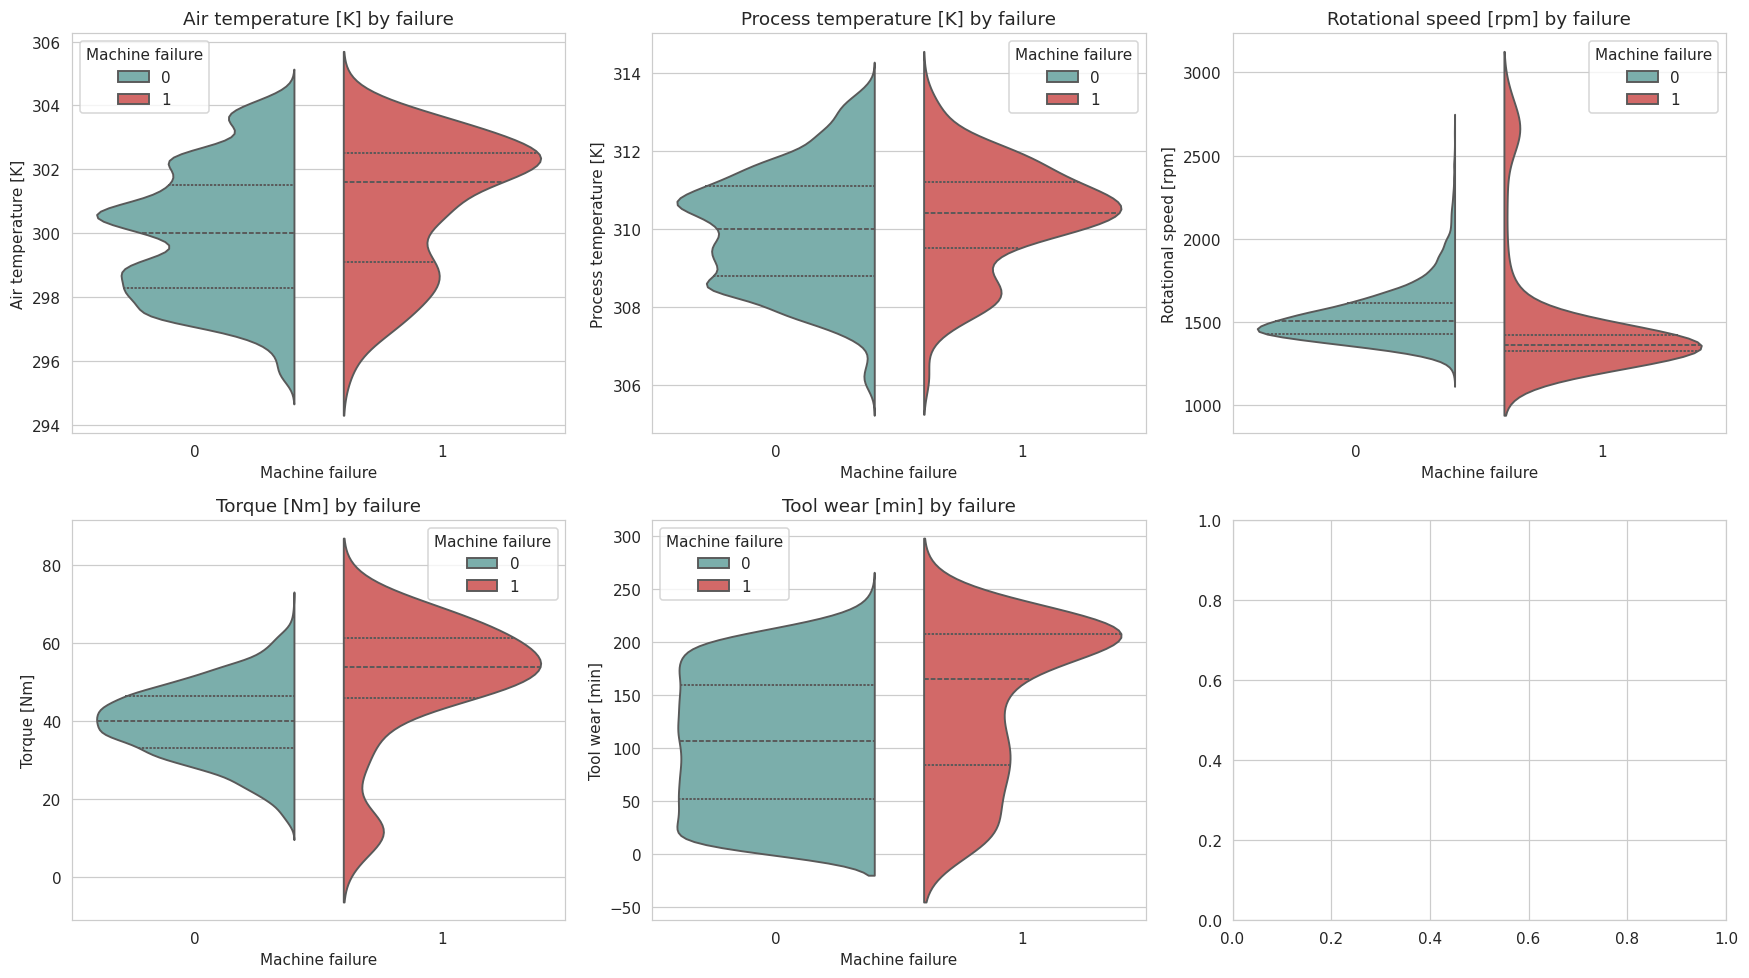

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for i, c in enumerate(num_cols):
    sns.violinplot(data=df, x="Machine failure", y=c, hue="Machine failure", split=True, inner="quartile",
                   palette={0: "#72b7b2", 1: "#e45756"}, ax=axes.flatten()[i])
    axes.flatten()[i].set_title(f"{c} by failure")
    axes.flatten()[i].set_xlabel("Machine failure")
plt.tight_layout()
plt.show()

## 7. 衍生特徵

- **Power (W)** = Torque [Nm] × Angular velocity [rad/s] = Torque × Rotational speed × π / 30
- **Temp diff** = Process temperature − Air temperature

觀察其與失敗標籤的相關性，驗證業務邏輯（功率過高/過低導致失敗、溫差過小導致散熱失敗）。

Correlations with Machine failure:
   Air temperature [K]: +0.0826
  Process temperature [K]: +0.0359
  Rotational speed [rpm]: -0.0442
           Torque [Nm]: +0.1913
       Tool wear [min]: +0.1054
             Power (W): +0.1760
             Temp diff: -0.1117


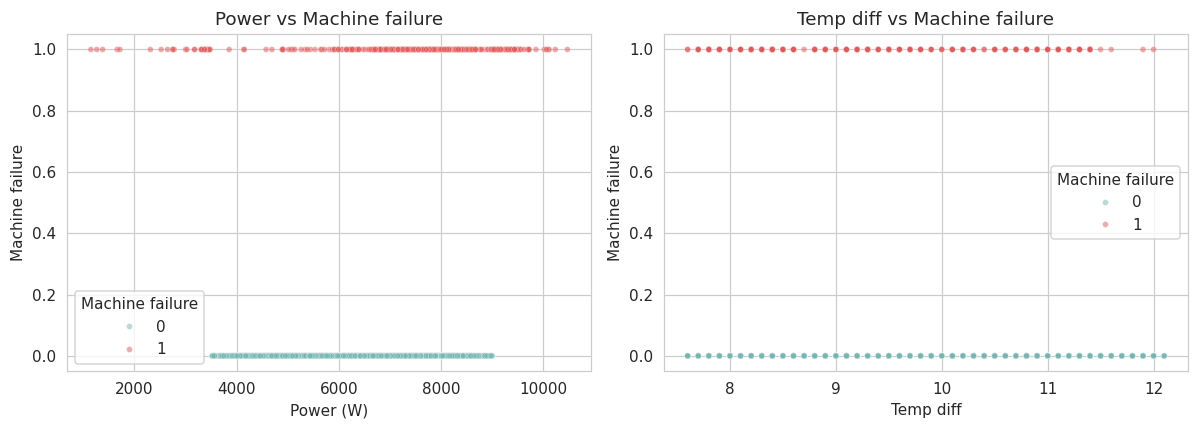

In [15]:
df = df.copy()
df["Power (W)"] = df["Torque [Nm]"] * (df["Rotational speed [rpm]"] * np.pi / 30)
df["Temp diff"] = df["Process temperature [K]"] - df["Air temperature [K]"]

derived_cols = ["Power (W)", "Temp diff"]
print("Correlations with Machine failure:")
for c in num_cols + derived_cols:
    print(f"  {c:>20}: {df[c].corr(df['Machine failure']):+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=df, x="Power (W)", y="Machine failure", hue="Machine failure",
                palette={0: "#72b7b2", 1: "#e45756"}, alpha=0.5, s=15, ax=axes[0])
axes[0].set_title("Power vs Machine failure")
sns.scatterplot(data=df, x="Temp diff", y="Machine failure", hue="Machine failure",
                palette={0: "#72b7b2", 1: "#e45756"}, alpha=0.5, s=15, ax=axes[1])
axes[1].set_title("Temp diff vs Machine failure")
plt.tight_layout()
plt.show()

## 8. 異常值偵測（IQR 法）

以四分位距（IQR）偵測數值變數的潛在異常點。

In [16]:
print("IQR-based outlier counts:")
for c in num_cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    print(f"  {c:>20}: Q1={q1:>8.2f} Q3={q3:>8.2f} IQR={iqr:>7.2f} bounds=[{lo:>8.2f}, {hi:>8.2f}] outliers={n_out:,}")

IQR-based outlier counts:
   Air temperature [K]: Q1=  298.30 Q3=  301.50 IQR=   3.20 bounds=[  293.50,   306.30] outliers=0
  Process temperature [K]: Q1=  308.80 Q3=  311.10 IQR=   2.30 bounds=[  305.35,   314.55] outliers=0
  Rotational speed [rpm]: Q1= 1423.00 Q3= 1612.00 IQR= 189.00 bounds=[ 1139.50,  1895.50] outliers=418
           Torque [Nm]: Q1=   33.20 Q3=   46.80 IQR=  13.60 bounds=[   12.80,    67.20] outliers=69
       Tool wear [min]: Q1=   53.00 Q3=  162.00 IQR= 109.00 bounds=[ -110.50,   325.50] outliers=0


## 9. 總結與發現

In [17]:
print("=" * 60)
print("EDA KEY FINDINGS")
print("=" * 60)
print(f"1. Dataset: {df.shape[0]:,} rows x {df.shape[1]} columns, no missing values, no duplicates.")
print(f"2. Machine failure rate: {df['Machine failure'].mean():.2%} (failure: {int(df['Machine failure'].sum()):,}, normal: {int((df['Machine failure']==0).sum()):,}).")
print("3. Failure mode counts: " + ", ".join(f"{c}={int(df[c].sum())}" for c in failure_modes))
print("4. Type distribution: " + ", ".join(f"{k}={int(v)}" for k, v in df["Type"].value_counts().items()))
print("   Failure rate by Type: " + ", ".join(f"{k}={v:.2%}" for k, v in df.groupby("Type")["Machine failure"].mean().items()))
print(f"5. Strongest correlation with failure: Torque [Nm] ({corr.loc['Machine failure','Torque [Nm]']:+.3f}), Power ({df['Power (W)'].corr(df['Machine failure']):+.3f}).")
print(f"   Negative: Rotational speed ({corr.loc['Machine failure','Rotational speed [rpm]']:+.3f}), Temp diff ({df['Temp diff'].corr(df['Machine failure']):+.3f}).")
print(f"6. Rotational speed vs Torque correlation: {corr.loc['Rotational speed [rpm]','Torque [Nm]']:+.3f} (strong negative).")
print(f"   Air temp vs Process temp correlation: {corr.loc['Air temperature [K]','Process temperature [K]']:+.3f}.")
print("7. IQR outliers: Rotational speed=418, Torque=69 (others minimal).")
print("=" * 60)

EDA KEY FINDINGS
1. Dataset: 10,000 rows x 16 columns, no missing values, no duplicates.
2. Machine failure rate: 3.39% (failure: 339, normal: 9,661).
3. Failure mode counts: TWF=46, HDF=115, PWF=95, OSF=98, RNF=19
4. Type distribution: L=6000, M=2997, H=1003
   Failure rate by Type: H=2.09%, L=3.92%, M=2.77%
5. Strongest correlation with failure: Torque [Nm] (+0.191), Power (+0.176).
   Negative: Rotational speed (-0.044), Temp diff (-0.112).
6. Rotational speed vs Torque correlation: -0.875 (strong negative).
   Air temp vs Process temp correlation: +0.876.
7. IQR outliers: Rotational speed=418, Torque=69 (others minimal).


**EDA 完成。** 詳細數據摘要請參見 `reports/eda_summary.md`。

---
*生成時間：由 Phase 1 EDA 管線自動產出*